# Four Recurring Tasks

**Question:** How well does a learner track four recurring tasks when it only has capacity for three of their representations?

Four fixed teachers each map 21 independent ±1 inputs through 10 LTUs to 10 linear outputs. Teacher weights are ±1 and every target has independent Gaussian noise of standard deviation 1. Every 10,000 examples, choose the next teachers. All tasks share input and output coordinates; no task ID is supplied.

The learner has **21 inputs → 30 LTUs → 10 linear outputs**, the same capacity as in the three-task notebook: enough features for three teachers, but not all four. Weights, optimizer state, and centering statistics persist across switches. All biases are weights on constant-1 inputs. Predictions are scored before learning each target.

Compare five SGD step sizes and network Autostep, using the same five seeds for every configuration. SGD uses fan-in initialization and sigmoid surrogate derivatives. Autostep uses **meta step 0.02, initial step 1e-5**, hidden weights uniform in ±1e-5, and uncompensated activation/derivative centering (rate 1e-3). Readouts start at zero. Autostep uses the `squared_inputs` implementation from the network Autostep notebooks, with normalization time constant 1e4.

**Privileged references:** shared linear Autostep readouts of fixed, true teacher features, centered at 0.5. One sees the 30 features of the first three teachers in the cycle (the learner's capacity), so every seed misses the fourth block of each cycle; the other sees all 40. Neither receives the active task ID nor correct output weights. Only their readouts learn, with the same Autostep settings and five seeds. They measure achievable readout adaptation with perfect features; they are not proven optimal bounds. Noise RMSE 1 is a lower bound, not the expected online optimum after unannounced switches.

Methods share teachers, switches, inputs and noise for matching seed IDs. The first plot shows every SGD rate. The second compares the SGD rate with the lowest mean per-seed RMSE over the final 100k examples against Autostep and both ideal-feature baselines, using the same runs without retraining.

In [1]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 4
N_HIDDEN = 3 * WIDTH  # capacity for three of the four teachers

# Autostep: uncompensated centering and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = 1e-5, 0.02, 1e-3

# Training
STEPS = 1_000_000
PLOT_STEPS = 80_000  # steps shown at the start and at the end of each plot
PERIOD = 10_000
BLOCKS = STEPS // PERIOD
WINDOW = 1000
SGD_EXPONENTS = (-9, -8, -7, -6, -5)
SGD_RATES = [2.**p for p in SGD_EXPONENTS]
N_SEEDS = 5
assert STEPS % PERIOD == 0 and PERIOD % WINDOW == 0

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > 0).astype(jnp.float32)

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes = [], [], []
    for w, mean, slope in zip(weights[:-1], learner.means, learner.slopes):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Same uncompensated centering and centered surrogate as network_autostep.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
            slope = slope + EMA_RATE * (derivative[:, None] * jax.lax.stop_gradient(source) - slope)
            correction = jnp.sum(slope * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
        means.append(mean)
        slopes.append(slope)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, rate, method, known_tasks=0):
    # known_tasks > 0 trains a reference readout of the true features of the first known_tasks teachers in the cycle.
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    task_id = jax.random.randint(schedule_key, (), 0, N_TASKS)
    if known_tasks:
        # Counting from the first task makes every seed miss the same blocks.
        known = teachers[0][(task_id + jnp.arange(known_tasks)) % N_TASKS]
        weights = (jnp.zeros((N_OUTPUTS, known_tasks * WIDTH + 1)),)
        learner = Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None, (), ())
    else:
        learner = init_learner(learner_key, (N_HIDDEN,), method)

    def block(carry, block_id):
        learner, rng, task_id = carry
        task_id = jnp.where(block_id == 0, task_id, (task_id + 1) % N_TASKS)
        teacher = jax.tree.map(lambda w: w[task_id], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            if known_tasks:
                # The known teachers' true features, with no indication of which task is active.
                x = (jnp.einsum('thi,i->th', known, x) > 0).astype(jnp.float32).reshape(-1) - .5
            learner, mse = update(learner, x, y, method, rate)
            return (learner, rng), (mse, learner.opt.beta if method == 'Autostep' else ())

        def record(carry, _):
            # Window means of the MSE and of every weight's ln(step size).
            carry, records = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, jax.tree.map(lambda r: r.mean(axis=0), records)
        (learner, rng), records = jax.lax.scan(record, (learner, rng), length=PERIOD // WINDOW)
        return (learner, rng, task_id), records

    _, records = jax.lax.scan(block, (learner, rng, task_id), jnp.arange(BLOCKS))
    return records


@partial(jax.jit, static_argnames=('method', 'known_tasks'))
def train_many(seeds, rates, method, known_tasks=0):
    one = partial(train, method=method, known_tasks=known_tasks)
    # Inner vmap: seeds; outer vmap: step sizes.
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(seeds, rates)


def run(method, rates=None, known_tasks=0):
    started = perf_counter()
    rates = jnp.asarray([INIT_RATE] if rates is None else rates, dtype=jnp.float32)
    mse, beta = jax.tree.map(np.asarray, train_many(jnp.arange(N_SEEDS), rates, method, known_tasks))
    assert np.isfinite(mse).all()
    print(f'{method}{f" ideal features of {known_tasks} tasks" if known_tasks else ""}: {perf_counter() - started:.1f}s including compilation')
    return mse, beta

In [6]:
started = perf_counter()
sgd, _ = run('SGD', rates=SGD_RATES)
autostep, autostep_beta = run('Autostep')
reference_3, _ = run('Autostep', known_tasks=3)
reference_4, _ = run('Autostep', known_tasks=N_TASKS)
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'four_recurring_tasks.npz', sgd=sgd, autostep=autostep,
                    reference_3=reference_3, reference_4=reference_4, rates=SGD_RATES, period=PERIOD,
                    window=WINDOW, seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')
assert seconds < 120, 'Simplify the experiment before extending it.'

SGD: 13.1s including compilation
Autostep: 24.8s including compilation
Autostep ideal features of 3 tasks: 17.4s including compilation
Autostep ideal features of 4 tasks: 18.6s including compilation
Complete comparison: 73.9s including compilation.


## Plots

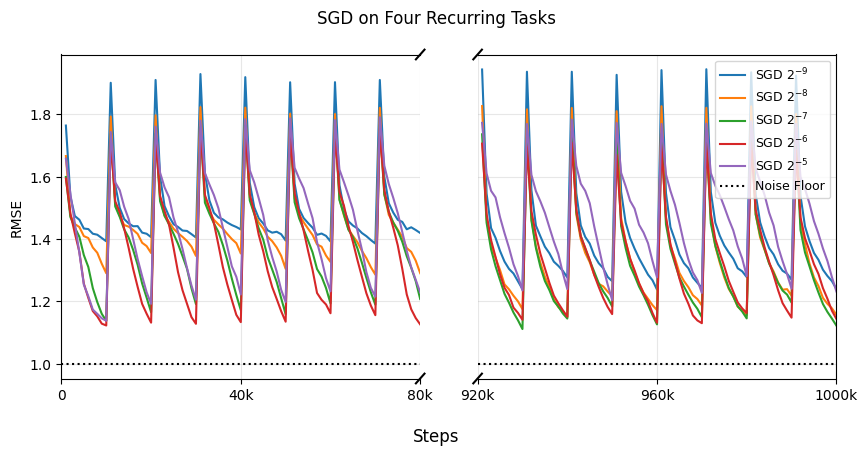

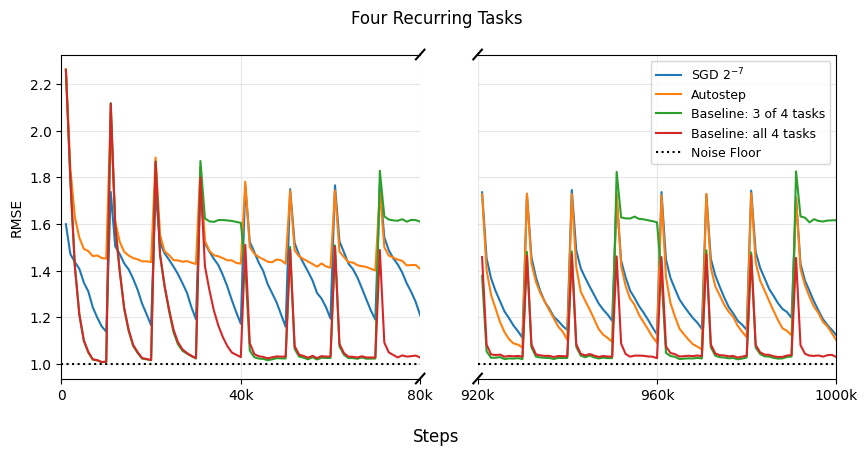

SGD $2^{-9}$: last 12 blocks 1.4325; preceding 12 1.4350
SGD $2^{-8}$: last 12 blocks 1.3520; preceding 12 1.3520
SGD $2^{-7}$: last 12 blocks 1.3276; preceding 12 1.3277
SGD $2^{-6}$: last 12 blocks 1.3330; preceding 12 1.3395
SGD $2^{-5}$: last 12 blocks 1.4708; preceding 12 1.4749
Autostep: last 12 blocks 1.2795; preceding 12 1.2812
Ideal-feature baseline, 3 of 4 tasks: last 12 blocks 1.2434; preceding 12 1.2425
Ideal-feature baseline, all 4 tasks: last 12 blocks 1.0894; preceding 12 1.0890
Comparison uses SGD 2^(-7), chosen by final-100k RMSE from the plotted sweep.


In [10]:
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
sgd_labels = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS]
late_scores = np.sqrt(sgd[:, :, -10:].mean(axis=(2, 3))).mean(axis=1)
best = int(np.argmin(late_scores))


def plot_broken_time(curves, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True,
                             gridspec_kw={'wspace': .16})
    for ax, (left, right) in zip(axes, ((0, PLOT_STEPS), (STEPS - PLOT_STEPS, STEPS))):
        visible = (x > left) & (x <= right)
        for label, values in curves:
            values = values.reshape(len(values), -1)
            ax.plot(x[visible], np.sqrt(values[:, visible]).mean(axis=0), label=label)
        ax.axhline(1., color='black', ls=':', label='Noise Floor')
        ax.set_xlim(left, right)
        ticks = np.linspace(left, right, 3)
        ax.set_xticks(ticks, ['0' if t == 0 else f'{t / 1000:g}k' for t in ticks])
        ax.grid(True, alpha=.3)
    axes[0].spines['right'].set_visible(False)
    axes[1].spines['left'].set_visible(False)
    axes[1].tick_params(axis='y', left=False)
    # Diagonal bars mark the omitted middle interval; the two time spans are equal.
    for ax, side in ((axes[0], 1), (axes[1], 0)):
        for height in (0, 1):
            ax.plot((side-.012, side+.012), (height-.015, height+.015),
                    transform=ax.transAxes, color='black', clip_on=False, lw=1.5)
    axes[0].set_ylabel('RMSE')
    axes[1].legend(fontsize=9)
    fig.suptitle(title)
    fig.supxlabel('Steps')
    fig.subplots_adjust(bottom=.16, top=.88)
    plt.show()


plot_broken_time(list(zip(sgd_labels, sgd)), 'SGD on Four Recurring Tasks')
plot_broken_time([(sgd_labels[best], sgd[best]),
                  ('Autostep', autostep[0]),
                  ('Baseline: 3 of 4 tasks', reference_3[0]),
                  ('Baseline: all 4 tasks', reference_4[0])],
                 'Four Recurring Tasks')
for label, values in list(zip(sgd_labels, sgd)) + [('Autostep', autostep[0]), ('Ideal-feature baseline, 3 of 4 tasks', reference_3[0]),
                                                   ('Ideal-feature baseline, all 4 tasks', reference_4[0])]:
    late = np.sqrt(values[:, -12:].mean(axis=(1, 2)))
    previous = np.sqrt(values[:, -24:-12].mean(axis=(1, 2)))
    print(f'{label}: last 12 blocks {late.mean():.4f}; preceding 12 {previous.mean():.4f}')
print(f'Comparison uses SGD 2^({SGD_EXPONENTS[best]}), chosen by final-100k RMSE from the plotted sweep.')

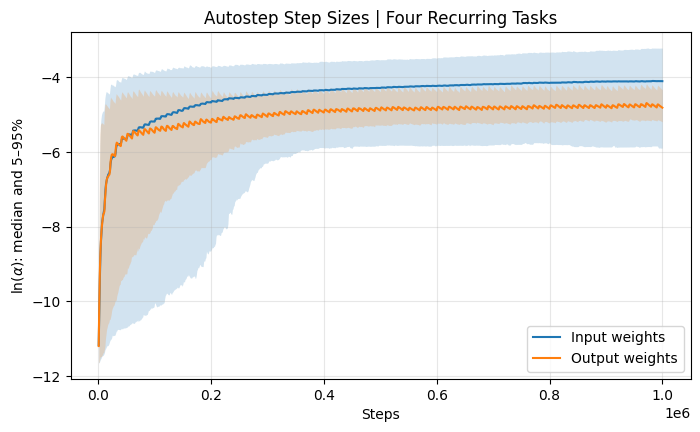

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, beta in zip(('Input weights', 'Output weights'), autostep_beta):
    # Pool every weight of every seed: (window, seed x weight).
    beta = np.moveaxis(beta[0].reshape(N_SEEDS, len(x), -1), 1, 0).reshape(len(x), -1)
    line, = ax.plot(x, np.median(beta, axis=1), label=label)
    ax.fill_between(x, *np.percentile(beta, [5, 95], axis=1), color=line.get_color(), alpha=.2, lw=0)
ax.set_xlabel('Steps')
ax.set_ylabel(r'$\ln(\alpha)$: median and 5–95%')
ax.set_title('Autostep Step Sizes | Four Recurring Tasks')
ax.grid(True, alpha=.3)
ax.legend()
plt.show()